# Sampling

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns 
import matplotlib.pyplot as plt 
%matplotlib inline

sns. set_style('whitegrid')
#load titanic dataset
titanic = sns. load_dataset('titanic')

titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [12]:
#only keep first 7 columns (including "fare")
titanic=titanic.iloc[:,:7]
titanic

,survived,pclass,sex,age,sibsp,parch,fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000
887,1,1,female,19.0,0,0,30.0000
888,0,3,female,NaN,1,2,23.4500
889,1,1,male,26.0,0,0,30.0000


In [13]:
#apply one hot encoding to feature "sex"
#Hint: see "transformation" lab if you struggle with this one
sex_oh_encoded = pd.get_dummies(titanic['sex'], prefix='sex')

#replace nominal feature "sex" with numeric feature "sex"
#join new features to original data frame
titanic=titanic.join(sex_oh_encoded, lsuffix='_df', rsuffix='_df2')

#titanic['sex']=sex_oh_encoded
titanic=titanic.drop('sex',axis=1)

titanic

,survived,pclass,age,sibsp,parch,fare,sex_female,sex_male
0,0,3,22.0,1,0,7.2500,0,1
1,1,1,38.0,1,0,71.2833,1,0
2,1,3,26.0,0,0,7.9250,1,0
3,1,1,35.0,1,0,53.1000,1,0
4,0,3,35.0,0,0,8.0500,0,1
...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,0,1
887,1,1,19.0,0,0,30.0000,1,0
888,0,3,NaN,1,2,23.4500,1,0
889,1,1,26.0,0,0,30.0000,0,1


# Simple random sampling without replacement

In [14]:
#show shape of the dataset
titanic.shape

(891, 8)

In [15]:
#Split titanic dataset using random sampling without replacement
#training set should be 500 rows
training_size=(titanic.shape[0]-500)/titanic.shape[0]
titanic_train, titanic_test = train_test_split(titanic, test_size=training_size, random_state=1)

print("Shape of training sample: ",titanic_train.shape)
print("Shape of testing sample: ",titanic_test.shape)

Shape of training sample:  (500, 8)
Shape of testing sample:  (391, 8)


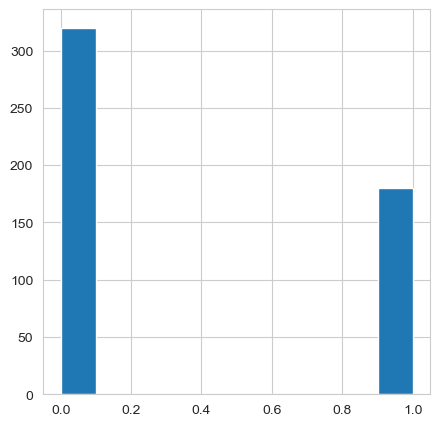

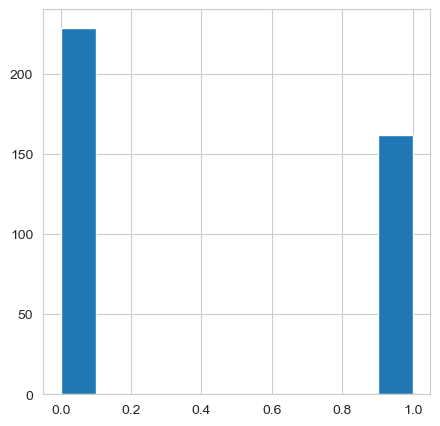

In [16]:
#show histograms for the label "survived" in both samples
titanic_train['survived'].hist(figsize=(5,5))
plt.show()
titanic_test['survived'].hist(figsize=(5,5))
plt.show()

# Balanced Sampling

In [17]:
#count the number of different values for the label "survived" in titanic dataset
titanic['survived'].value_counts()

0    549
1    342
Name: survived, dtype: int64

In [18]:
#split data to features and label
X= titanic.iloc[:,1:]
y= titanic['survived']

In [ ]:
#!pip install imblearn

In [19]:
from imblearn.over_sampling import RandomOverSampler

# Create an instance of RandomOverSampler
oversampler = RandomOverSampler(random_state=0)

# Fit and apply oversampling to the data
X_resampled, y_resampled = oversampler.fit_resample(X, y)

# Print the original and resampled class distributions
print('Original class distribution:', {i:sum(y==i) for i in range(3)})
print('Resampled class distribution:', {i:sum(y_resampled==i) for i in range(3)})

Original class distribution: {0: 549, 1: 342, 2: 0}
Resampled class distribution: {0: 549, 1: 549, 2: 0}


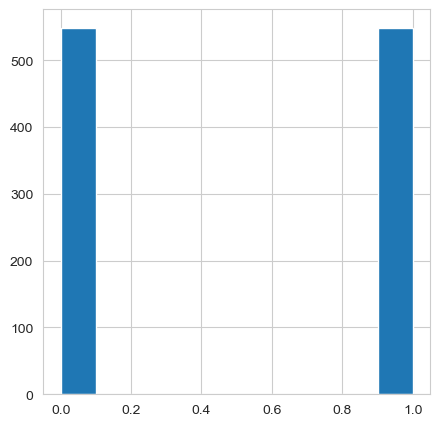

In [20]:
#show histograms for the label "survived" after oversampling
y_resampled.hist(figsize=(5,5))
plt.show()

# Stratified Sampling

In [ ]:
#Apply Stratified Sampling to data set and split to training and test data (training data should be 70%)
titanic_train, titanic_test = train_test_split(titanic, test_size=0.3, random_state=1,stratify=titanic['survived'])

#Print shape of trainng and test sample
print("Shape of training sample: ",titanic_train.shape)
print("Shape of testing sample: ",titanic_test.shape)

#Print distribution of lavel values in training and test sample
print("\nDistribution of labels in training sample\n",titanic_train['survived'].value_counts())
print("Distribution of labels in test sample\n",titanic_test['survived'].value_counts())

# Split into training - validation - test data

In [ ]:
#Apply Stratified Sampling to data set and split to training, validation and test data
#training_sample 30%, validation sample 30%, test sample 40%
titanic_train, titanic_test = train_test_split(titanic, test_size=0.4, random_state=1)
titanic_train, titanic_val = train_test_split(titanic_train, test_size=0.5, random_state=1)

print("Shape of training sample: ",titanic_train.shape)
print("Shape of validation sample: ",titanic_val.shape)
print("Shape of testing sample: ",titanic_test.shape)

# Cross Validation

In [ ]:
#Apply stratified cross validation to data set
#k should be 4
import numpy as np
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=4)
skf.get_n_splits(titanic)

print(skf)

for i, (train_index, test_index) in enumerate(skf.split(titanic.iloc[:,1:],titanic['survived'])):
    print("\n")
    print(f"Fold {i}:")
    print(f"  Train: index={train_index}")
    print(f"  Test:  index={test_index}")